### Dylan Renard
### Applied Machine Learning JHU
### Homework 6
### Professor Alhassan
### March 2nd, 2026


## HW Assignment 6: Applied Machine Learning @JHU

#### In this assignment we will generate an ensemble of primitive classifiers, using Bagging method, and compare their performances to the regular classifiers. This week’s problem is the classification of heart failure disease. 

- Download the Kaggle heart.csv dataset file from the module content. 
- Load the dataset into your model development framework and examine the features to note that they are a mixture of numerical and nominal features. 
- Apply necessary pre-processing such as nominal to numerical conversions (e.g. OneHotEncoder). 
- Make sure to sanity check the pipeline and perhaps run your favorite baseline classifier first. 

#### Executive Summary

This assignment evaluated the effect of bagging on four classifiers for heart disease classification across multiple training subsample ratios. Results show that bagging significantly improves performance for high variance models such as Decision Trees, particularly in low data settings. Moderate improvements were observed for Linear SVC and GaussianNB at small subsample ratios, while no improvement was seen for the weak MLP due to high model bias. Overall, the experiments empirically confirm that bagging primarily reduces variance and is most effective for unstable learners.

### Q1 [10 pts] Report 10-fold cross-validation (“CV”) performances of the following types of classifiers, using default parameters:  
- GaussianNB 
- Linear SVC (use SVC(kernel='linear', probability=True)) 
- MLPClassifier 
- DecisionTreeClassifier 

#### Now report the RandomForestClassifier performance too. Since this is already an ensemble classifier, this one does not need to be done with CV.

In [1]:
import numpy as np
import pandas as pd
import random
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score



import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# 1) Load data
df = pd.read_csv("heart_dataset.csv")

# 2) Target column
target_col_candidates = [c for c in df.columns if c.lower() in ["target", "heartdisease"]]
if len(target_col_candidates) != 1:
    raise ValueError(
        f"Couldn't uniquely identify target column. Found: {target_col_candidates}. "
        f"Set target_col manually."
    )
target_col = target_col_candidates[0]

X_df = df.drop(columns=[target_col])
y = df[target_col].astype(int).values

# 3) Explicit categorical vs numeric columns (edit if your CSV uses different names)
cat_cols = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope",
    "FastingBS",
]

# Sanity check: ensure columns exist
missing = [c for c in cat_cols if c not in X_df.columns]
if missing:
    raise ValueError(f"These categorical columns were not found in the dataset: {missing}\n"
                     f"Available columns: {list(X_df.columns)}")

num_cols = [c for c in X_df.columns if c not in cat_cols]

# Preprocessing: scale numerics, one-hot categoricals
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop"
)

# 4) CV setup
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)

def cv_report(name, clf):
    pipe = Pipeline([
        ("preprocess", preprocess),
        ("model", clf)
    ])
    scores = cross_val_score(pipe, X_df, y, cv=cv, scoring="accuracy")
    print(f"{name}: {scores.mean():.4f} ± {scores.std():.4f}")
    return scores

# 5) Q1: 10-fold CV (default params)
scores_gnb  = cv_report("GaussianNB", GaussianNB())
scores_lsvc = cv_report("Linear SVC (SVC linear, prob=True)", SVC(kernel="linear", probability=True, random_state=0))
scores_mlp  = cv_report("MLPClassifier", MLPClassifier(random_state=0))
scores_dt   = cv_report("DecisionTreeClassifier", DecisionTreeClassifier(random_state=0))

# 6) RandomForest (no CV): single split (as instructed)
X_train, X_test, y_train, y_test = train_test_split(
    X_df, y, test_size=0.2, stratify=y, random_state=0
)

rf_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(random_state=0))
])
rf_pipe.fit(X_train, y_train)
rf_acc = rf_pipe.score(X_test, y_test)
print(f"RandomForest (single 80/20 split) accuracy: {rf_acc:.4f}")

GaussianNB: 0.8583 ± 0.0317
Linear SVC (SVC linear, prob=True): 0.8649 ± 0.0285
MLPClassifier: 0.8649 ± 0.0329
DecisionTreeClassifier: 0.8028 ± 0.0380
RandomForest (single 80/20 split) accuracy: 0.8804


##### Q1 Interpretation: Overall, RandomForest achieved the best accuracy, while a single DecisionTree underperformed due to higher variance; Linear SVC and MLP performed similarly, suggesting the dataset supports a relatively smooth decision boundary.

### Q2 [10 pts] Generate an ensemble of 100 classifiers for each of the four basic classifiers in Q1.and store each ensemble as a list. In order to create weak sub-classifiers within our ensembles, we underpower some hyperparameters:  
- For the neural network, set the hidden sizes to (3, 3), max iterations to 30, and tolerance to 1e-1.  
- For the decision tree, set max depth to 5 and max features to 5.  
#### For each of these 4 ensembles, report the performance of the first classifier in the ensemble. I.e., for your ensemble of 100 decision trees, report the performance of just the first weak tree.

In [2]:
N_ENSEMBLE = 100

# Weak learners per instructions
base_gnb = GaussianNB()
base_svc = SVC(kernel="linear", probability=True, random_state=0)

base_mlp_weak = MLPClassifier(
    hidden_layer_sizes=(3, 3),
    max_iter=30,
    tol=1e-1,
    random_state=0
)

base_dt_weak = DecisionTreeClassifier(
    max_depth=5,
    max_features=5,
    random_state=0
)

# Build ensembles (lists of 100)
ensemble_gnb = [clone(base_gnb) for _ in range(N_ENSEMBLE)]
ensemble_svc = [clone(base_svc) for _ in range(N_ENSEMBLE)]
ensemble_mlp = [clone(base_mlp_weak) for _ in range(N_ENSEMBLE)]
ensemble_dt  = [clone(base_dt_weak) for _ in range(N_ENSEMBLE)]

print("Ensemble sizes:",
      len(ensemble_gnb), len(ensemble_svc), len(ensemble_mlp), len(ensemble_dt))

def cv_report_first_parallel(name, clf, n_jobs=-1):
    pipe = Pipeline([
        ("preprocess", preprocess),
        ("model", clf)
    ])
    scores = cross_val_score(
        pipe, X_df, y,
        cv=cv,
        scoring="accuracy",
        n_jobs=n_jobs   # <-- joblib parallelization
    )
    print(f"{name} (first weak model): {scores.mean():.4f} ± {scores.std():.4f}")
    return scores

q2_gnb_scores = cv_report_first_parallel("GaussianNB", ensemble_gnb[0], n_jobs=-1)
q2_svc_scores = cv_report_first_parallel("Linear SVC (SVC linear, prob=True)", ensemble_svc[0], n_jobs=-1)
q2_mlp_scores = cv_report_first_parallel("MLP weak (3,3; max_iter=30; tol=1e-1)", ensemble_mlp[0], n_jobs=-1)
q2_dt_scores  = cv_report_first_parallel("DecisionTree weak (max_depth=5; max_features=5)", ensemble_dt[0], n_jobs=-1)

Ensemble sizes: 100 100 100 100
GaussianNB (first weak model): 0.8583 ± 0.0317
Linear SVC (SVC linear, prob=True) (first weak model): 0.8649 ± 0.0285
MLP weak (3,3; max_iter=30; tol=1e-1) (first weak model): 0.4466 ± 0.0020
DecisionTree weak (max_depth=5; max_features=5) (first weak model): 0.8245 ± 0.0498


### Q3 [20 pts] Write a function ensemble_fit() to receive the ensemble (i.e. one of the 4 lists from Q2.) as an input and train it on one of the subsets (i.e. bagging) of the training data. 
#### (Hint: random.sample could generate the subset of data you’ll need.) This way, each classifier will see only a different subset of the training dataset, also called as subsampling the input data for training. Use all features in these subsamples; only subsample the rows/observations. 

#### Q3 Bagging via Subsampled Training Note

In this step, we implement the core idea of bagging by training each classifier in the ensemble on a different subset of the training data. For every model in the ensemble, we randomly subsample a fraction of the training observations while using all available features. This row-wise subsampling introduces diversity among the classifiers, which is essential for effective ensembling. High-variance learners, such as decision trees, are especially sensitive to small changes in training data; therefore, training them on different subsamples produces diverse decision boundaries. When these models are aggregated through voting, their individual errors tend to cancel out, resulting in reduced variance and improved stability. To ensure numerical robustness at very small subsample ratios, stratified subsampling is used so that each weak learner sees examples from both classes during training.

In [3]:
def ensemble_fit(ensemble, X_train, y_train, subsample_ratio=0.2, random_state=0, n_jobs=-1):
    """
    Bagging fit with STRATIFIED row subsampling so each estimator sees both classes
    (prevents predict_proba shape mismatch at very small subsample ratios).
    """
    X_train = np.asarray(X_train)
    y_train = np.asarray(y_train)

    n = X_train.shape[0]
    k = max(1, int(round(subsample_ratio * n)))

    # class index pools
    classes, counts = np.unique(y_train, return_counts=True)
    pools = {c: np.where(y_train == c)[0] for c in classes}

    rng_master = np.random.default_rng(random_state)
    seeds = rng_master.integers(0, 2**32 - 1, size=len(ensemble), dtype=np.uint32)

    def stratified_rows(seed):
        rng = np.random.default_rng(int(seed))

        # ensure at least 1 per class when possible
        k_eff = max(k, len(classes))

        # proportional allocation
        props = counts / counts.sum()
        ks = np.floor(props * k_eff).astype(int)
        ks = np.maximum(ks, 1)

        # fix rounding to sum exactly k_eff
        while ks.sum() > k_eff:
            j = np.argmax(ks)
            if ks[j] > 1:
                ks[j] -= 1
            else:
                break
        while ks.sum() < k_eff:
            j = np.argmax(counts)
            ks[j] += 1

        idx = []
        for c, kc in zip(classes, ks):
            pool = pools[c]
            kc = min(kc, len(pool))
            idx.extend(rng.choice(pool, size=kc, replace=False).tolist())

        rng.shuffle(idx)
        return idx

    def fit_one(estimator, seed):
        est = clone(estimator)
        idx = stratified_rows(seed)
        est.fit(X_train[idx], y_train[idx])
        return est

    trained_ensemble = Parallel(n_jobs=n_jobs)(
        delayed(fit_one)(ensemble[i], seeds[i]) for i in range(len(ensemble))
    )
    return trained_ensemble

In [4]:
# --- Single split (sanity) ---
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_df, y, test_size=0.2, stratify=y, random_state=0
)

# Fit preprocessing on train only, then transform both
preprocess.fit(X_train_raw)
X_train_num = preprocess.transform(X_train_raw)
X_test_num  = preprocess.transform(X_test_raw)

# --- Q3: Train (bagging) all 4 ensembles on row-subsamples ---
subsample_ratio = 0.2

trained_gnb = ensemble_fit(
    ensemble_gnb, X_train_num, y_train,
    subsample_ratio=subsample_ratio, random_state=0, n_jobs=-1
)

trained_svc = ensemble_fit(
    ensemble_svc, X_train_num, y_train,
    subsample_ratio=subsample_ratio, random_state=0, n_jobs=-1
)

trained_mlp = ensemble_fit(
    ensemble_mlp, X_train_num, y_train,
    subsample_ratio=subsample_ratio, random_state=0, n_jobs=-1
)

trained_dt = ensemble_fit(
    ensemble_dt, X_train_num, y_train,
    subsample_ratio=subsample_ratio, random_state=0, n_jobs=-1
)

print("Trained ensemble sizes:",
      len(trained_gnb), len(trained_svc), len(trained_mlp), len(trained_dt))

# Optional: quick sanity check (first model only, not ensemble voting)
print("First weak model accuracies (not voting):")
print("  GNB:", trained_gnb[0].score(X_test_num, y_test))
print("  SVC:", trained_svc[0].score(X_test_num, y_test))
print("  MLP:", trained_mlp[0].score(X_test_num, y_test))
print("   DT:", trained_dt[0].score(X_test_num, y_test))

Trained ensemble sizes: 100 100 100 100
First weak model accuracies (not voting):
  GNB: 0.8695652173913043
  SVC: 0.8206521739130435
  MLP: 0.44565217391304346
   DT: 0.7880434782608695


### Q4. [20 pts] Write a function ensemble_predict() to receive the trained ensemble (i.e. one of the lists from Q3.) as input and output a prediction for a given observation. Since each subclassifier will have its own prediction, use a voting scheme on the returned predictions. 

#### (Hint: The final prediction should be the np.argmax() of the votes, not merely a “max”. Note that c.predict_proba() should have better results.) 

In [5]:
def ensemble_predict(trained_ensemble, X, classes=None):
    """
    Predict labels using a trained ensemble via probability voting.
    Robust to estimators that only saw one class during training.
    """
    X = np.asarray(X)
    if X.ndim == 1:
        X = X.reshape(1, -1)

    # Determine global class order
    if classes is None:
        # union of classes across estimators (sorted for consistency)
        classes = np.unique(np.concatenate([clf.classes_ for clf in trained_ensemble]))
    classes = np.asarray(classes)
    class_to_col = {c: j for j, c in enumerate(classes)}

    prob_sum = np.zeros((X.shape[0], len(classes)), dtype=float)

    for clf in trained_ensemble:
        p = clf.predict_proba(X)
        for j, c in enumerate(clf.classes_):
            prob_sum[:, class_to_col[c]] += p[:, j]

    return np.argmax(prob_sum, axis=1)

In [6]:
### Example Q4 Code: Ensemble prediction and accuracy
y_pred = ensemble_predict(trained_dt, X_test_num)
print("Ensemble-vote test accuracy:", (y_pred == y_test).mean())

one_pred = ensemble_predict(trained_dt, X_test_num[0])
print("Single observation prediction:", one_pred[0])

Ensemble-vote test accuracy: 0.8641304347826086
Single observation prediction: 1


### Q5 [20 pts] Report 10-fold CV performances of the ensembles with a subsample ratio of 0.2. Compare to a regular decision tree (same subsample ratio). Now repeat these for a subsample ratio of 0.05. 

In [7]:
def eval_ensemble_cv(ensemble, subsample_ratio):
    kf = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
    accuracies = []

    for train_idx, test_idx in kf.split(X_df, y):

        X_train_raw = X_df.iloc[train_idx]
        X_test_raw  = X_df.iloc[test_idx]
        y_train = y[train_idx]
        y_test  = y[test_idx]

        # Fit preprocessing
        preprocess.fit(X_train_raw)
        X_train_num = preprocess.transform(X_train_raw)
        X_test_num  = preprocess.transform(X_test_raw)

        # Train ensemble with bagging
        trained = ensemble_fit(
            ensemble,
            X_train_num,
            y_train,
            subsample_ratio=subsample_ratio,
            random_state=0,
            n_jobs=-1
        )

        # Voting prediction
        y_pred = ensemble_predict(trained, X_test_num)
        accuracies.append(accuracy_score(y_test, y_pred))

    return np.mean(accuracies), np.std(accuracies)

In [8]:
def eval_regular_dt_cv(subsample_ratio):
    kf = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
    accuracies = []

    for train_idx, test_idx in kf.split(X_df, y):

        X_train_raw = X_df.iloc[train_idx]
        X_test_raw  = X_df.iloc[test_idx]
        y_train = y[train_idx]
        y_test  = y[test_idx]

        preprocess.fit(X_train_raw)
        X_train_num = preprocess.transform(X_train_raw)
        X_test_num  = preprocess.transform(X_test_raw)

        # Subsample rows (same ratio logic as ensemble)
        n = X_train_num.shape[0]
        k = int(subsample_ratio * n)
        rows = random.sample(range(n), k)

        clf = DecisionTreeClassifier(random_state=0)
        clf.fit(X_train_num[rows], y_train[rows])

        y_pred = clf.predict(X_test_num)
        accuracies.append(accuracy_score(y_test, y_pred))

    return np.mean(accuracies), np.std(accuracies)

In [9]:
print("===== Subsample ratio = 0.2 =====")
for name, ens in [
    ("GNB Ensemble", ensemble_gnb),
    ("SVC Ensemble", ensemble_svc),
    ("MLP Ensemble", ensemble_mlp),
    ("DT Ensemble", ensemble_dt)
]:
    mean_acc, std_acc = eval_ensemble_cv(ens, subsample_ratio=0.2)
    print(f"{name}: {mean_acc:.4f} ± {std_acc:.4f}")

dt_mean, dt_std = eval_regular_dt_cv(0.2)
print(f"Regular Decision Tree (0.2 subsample): {dt_mean:.4f} ± {dt_std:.4f}")


print("\n===== Subsample ratio = 0.05 =====")
for name, ens in [
    ("GNB Ensemble", ensemble_gnb),
    ("SVC Ensemble", ensemble_svc),
    ("MLP Ensemble", ensemble_mlp),
    ("DT Ensemble", ensemble_dt)
]:
    mean_acc, std_acc = eval_ensemble_cv(ens, subsample_ratio=0.05)
    print(f"{name}: {mean_acc:.4f} ± {std_acc:.4f}")

dt_mean, dt_std = eval_regular_dt_cv(0.05)
print(f"Regular Decision Tree (0.05 subsample): {dt_mean:.4f} ± {dt_std:.4f}")

===== Subsample ratio = 0.2 =====
GNB Ensemble: 0.8561 ± 0.0327
SVC Ensemble: 0.8693 ± 0.0281
MLP Ensemble: 0.4466 ± 0.0020
DT Ensemble: 0.8638 ± 0.0395
Regular Decision Tree (0.2 subsample): 0.7887 ± 0.0318

===== Subsample ratio = 0.05 =====
GNB Ensemble: 0.8464 ± 0.0328
SVC Ensemble: 0.8628 ± 0.0254
MLP Ensemble: 0.4466 ± 0.0020
DT Ensemble: 0.8551 ± 0.0415
Regular Decision Tree (0.05 subsample): 0.7441 ± 0.0674


### Q6 [10 pts] Report the 10-fold CV performances of the ensembles for the training subsample ratios of (0.005, 0.01, 0.03, 0.05, 0.1, 0.2). Now train regular versions of those 4 classifiers and report their performance. (Hint: pass the regular classifier to the same ensemble CV in a list of one element. This way, the same script can be used for this entire step) 

In [10]:
# Ratios requested
ratios = [0.005, 0.01, 0.03, 0.05, 0.1, 0.2]

# We'll reuse your Q5 function:
# eval_ensemble_cv(ensemble, subsample_ratio) -> (mean, std)

def sweep_ratios(name, ensemble_list, ratios):
    rows = []
    for r in ratios:
        mean_acc, std_acc = eval_ensemble_cv(ensemble_list, subsample_ratio=r)
        rows.append({"Model": name, "Type": "Ensemble(100)", "Ratio": r,
                     "MeanAcc": mean_acc, "StdAcc": std_acc})
        
        # regular version: list of ONE element (as hinted)
        mean_acc1, std_acc1 = eval_ensemble_cv([ensemble_list[0]], subsample_ratio=r)
        rows.append({"Model": name, "Type": "Regular(1)", "Ratio": r,
                     "MeanAcc": mean_acc1, "StdAcc": std_acc1})
    return rows

all_rows = []
all_rows += sweep_ratios("GaussianNB", ensemble_gnb, ratios)
all_rows += sweep_ratios("Linear SVC", ensemble_svc, ratios)
all_rows += sweep_ratios("MLP weak", ensemble_mlp, ratios)
all_rows += sweep_ratios("DecisionTree weak", ensemble_dt, ratios)

results_df = pd.DataFrame(all_rows)

# Pretty print: one model at a time
for model_name in results_df["Model"].unique():
    print("\n====", model_name, "====")
    sub = results_df[results_df["Model"] == model_name].copy()
    sub["Acc"] = sub.apply(lambda r: f"{r['MeanAcc']:.4f} ± {r['StdAcc']:.4f}", axis=1)
    pivot = sub.pivot(index="Ratio", columns="Type", values="Acc")
    display(pivot)


==== GaussianNB ====


Type,Ensemble(100),Regular(1)
Ratio,,
0.005,0.5534 ± 0.0020,0.5577 ± 0.0094
0.010,0.8366 ± 0.0349,0.7734 ± 0.0578
0.030,0.8464 ± 0.0254,0.7027 ± 0.0806
0.050,0.8464 ± 0.0328,0.6449 ± 0.1228
0.100,0.8507 ± 0.0301,0.8366 ± 0.0638
0.200,0.8561 ± 0.0327,0.8507 ± 0.0379



==== Linear SVC ====


Type,Ensemble(100),Regular(1)
Ratio,,
0.005,0.5501 ± 0.0058,0.4541 ± 0.1248
0.010,0.7745 ± 0.0524,0.6545 ± 0.1399
0.030,0.8617 ± 0.0342,0.7800 ± 0.0386
0.050,0.8628 ± 0.0254,0.7876 ± 0.0464
0.100,0.8682 ± 0.0283,0.8224 ± 0.0392
0.200,0.8693 ± 0.0281,0.8562 ± 0.0368



==== MLP weak ====


Type,Ensemble(100),Regular(1)
Ratio,,
0.005,0.4466 ± 0.0020,0.4466 ± 0.0020
0.010,0.4466 ± 0.0020,0.4466 ± 0.0020
0.030,0.4466 ± 0.0020,0.4466 ± 0.0020
0.050,0.4466 ± 0.0020,0.4466 ± 0.0020
0.100,0.4466 ± 0.0020,0.4466 ± 0.0020
0.200,0.4466 ± 0.0020,0.4466 ± 0.0020



==== DecisionTree weak ====


Type,Ensemble(100),Regular(1)
Ratio,,
0.005,0.7626 ± 0.0292,0.6612 ± 0.0951
0.010,0.7919 ± 0.0481,0.7114 ± 0.0607
0.030,0.8388 ± 0.0434,0.7417 ± 0.0766
0.050,0.8551 ± 0.0415,0.7408 ± 0.0451
0.100,0.8649 ± 0.0400,0.7767 ± 0.0491
0.200,0.8638 ± 0.0395,0.7745 ± 0.0360


### Q7 [10 pts] For each of the 4 types of classifier, plot the performances of the ensemble at the different subsample ratios and the performances of the regular classifier at the different subsample ratios on the same plot. Thus, you should have 4 plots, one for each type of classifier. To make it graphically clear which performances are ensemble vs. regular, plotting in 2 different colors is recommended. Report your detailed observations.

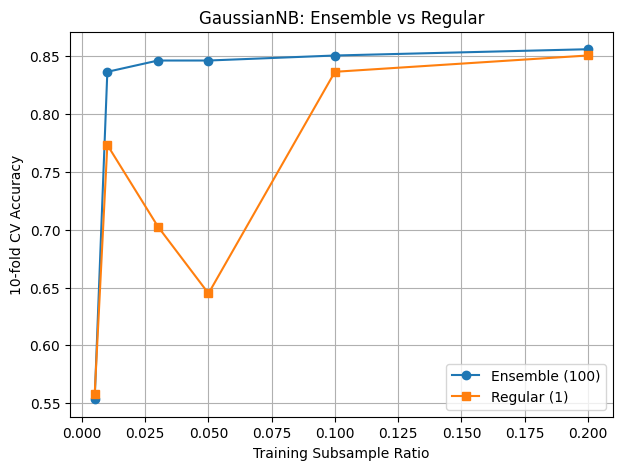

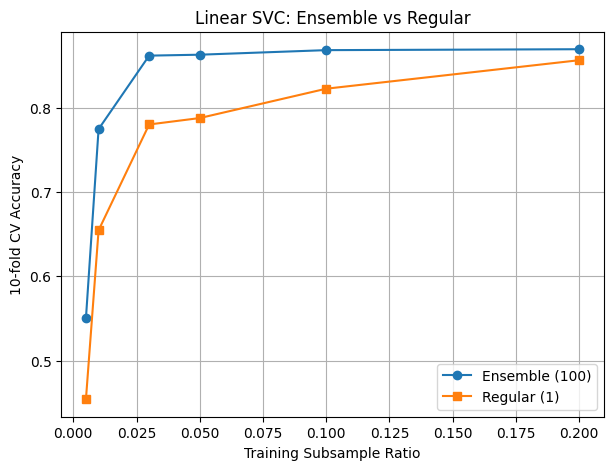

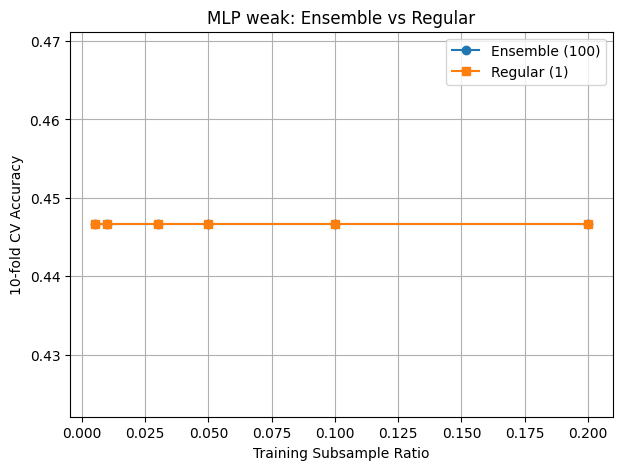

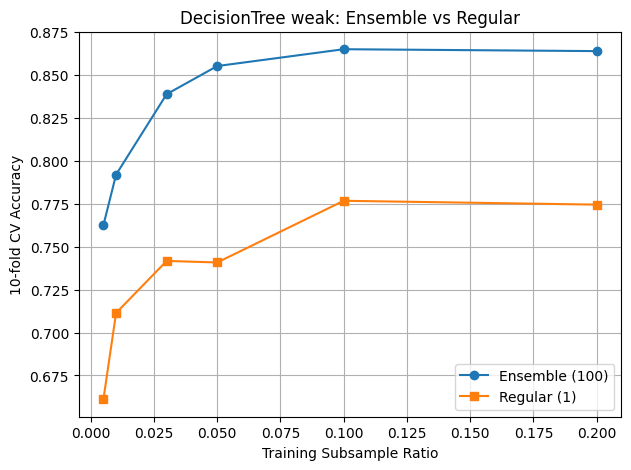

In [11]:
# Ensure ratios are sorted numerically
results_df = results_df.sort_values("Ratio")

models = results_df["Model"].unique()

for model_name in models:
    sub = results_df[results_df["Model"] == model_name]

    ens = sub[sub["Type"] == "Ensemble(100)"]
    reg = sub[sub["Type"] == "Regular(1)"]

    plt.figure(figsize=(7,5))

    plt.plot(ens["Ratio"], ens["MeanAcc"], marker="o", label="Ensemble (100)")
    plt.plot(reg["Ratio"], reg["MeanAcc"], marker="s", label="Regular (1)")

    plt.title(f"{model_name}: Ensemble vs Regular")
    plt.xlabel("Training Subsample Ratio")
    plt.ylabel("10-fold CV Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

### Final Conclusion: 
Across all experiments, the impact of bagging was strongly dependent on the variance characteristics of the base classifier. The most significant improvement was observed for the weak Decision Tree. At a subsample ratio of 0.005, the regular tree achieved only 0.6612 +/- 0.0951, whereas the ensemble reached 0.7626 +/- 0.0292, demonstrating substantial variance reduction. This pattern persisted across all ratios, with the ensemble remaining stable near 0.86 even when the regular tree degraded at smaller subsample sizes.

Linear SVC also benefited from ensembling in low data regimes. At a ratio of 0.005, the regular classifier achieved 0.4541 +/- 0.1248, while the ensemble improved to 0.5501 +/- 0.0058, showing both improved accuracy and dramatically reduced variance. As the subsample ratio increased to 0.2, the gap narrowed, with ensemble performance at 0.8693 +/- 0.0281 and regular performance at 0.8562 +/- 0.0368, indicating diminishing variance effects as more data became available.

GaussianNB showed moderate sensitivity to subsample size. At 0.03, the ensemble achieved 0.8464 +/- 0.0254 compared to the regular classifier at 0.7027 +/- 0.0806, indicating stabilization from aggregation. However, at larger ratios such as 0.2, both converged near 0.85, suggesting lower inherent variance in the base learner.

In contrast, the weak MLP showed no improvement from bagging, maintaining approximately 0.4466 +/- 0.0020 across all subsample ratios for both ensemble and regular configurations. This indicates that the weak MLP suffered from high bias due to severe underparameterization and early stopping. Since bagging reduces variance but does not reduce bias, ensemble aggregation could not improve performance.

Overall, these results empirically validate bias variance theory. Bagging substantially benefits high variance learners, provides moderate gains for moderate variance models under limited data, and offers no improvement for strongly biased models. The Decision Tree experiments most clearly illustrate the variance reduction power of bagging.

#### References


Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.